In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df= pd.read_csv('Social_Network_Ads.csv')

In [3]:
df = df.iloc[:,2:]

In [4]:
df.sample(6)

,Age,EstimatedSalary,Purchased
102,32,86000,0
60,27,20000,0
301,48,74000,1
130,31,58000,0
183,33,43000,0
83,35,88000,0


<h2>Train test split <h2/>

In [5]:
#here we do train test split 
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(df.drop('Purchased',axis=1),df['Purchased'],test_size=0.3,random_state=0)
X_train.shape,X_test.shape

((280, 2), (120, 2))

<h2>Standard Scaler <h2/>

In [6]:
#here we do feature scalling (standardization)
from sklearn.preprocessing import StandardScaler 
scaler = StandardScaler()
# here we will fit scaler to train the set ,it will learn parametre 
scaler.fit(X_train)
#transform train and test set
X_train_Scaled= scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [7]:
X_train_scaled = pd.DataFrame(X_train_Scaled, columns =X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled ,columns = X_test.columns)

In [8]:
np.round(X_train_scaled.describe(),1)

,Age,EstimatedSalary
count,280.0,280.0
mean,0.0,0.0
std,1.0,1.0
min,-1.9,-1.6
25%,-0.8,-0.8
50%,-0.1,0.0
75%,0.8,0.5
max,2.2,2.3


<h2>Eeffect of scalling <h2/>

Text(0.5, 1.0, 'Before Scalling')

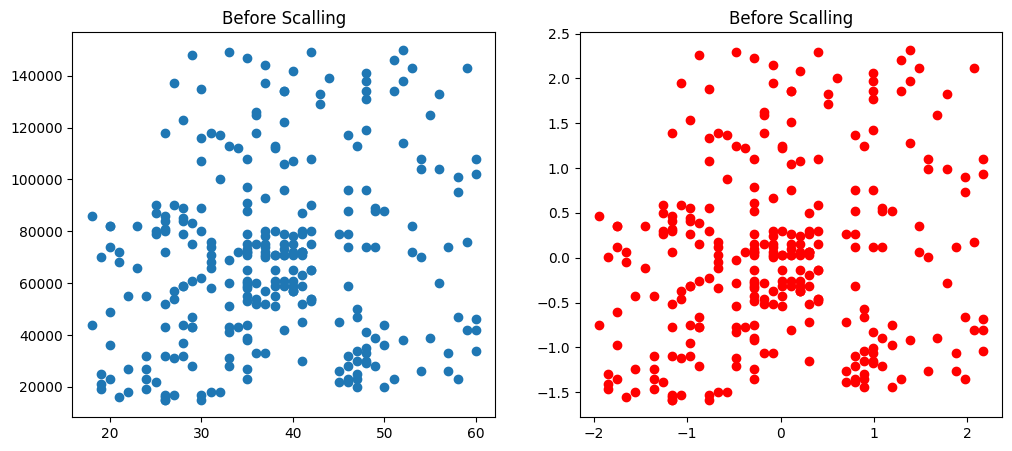

In [9]:
fig, (ax1, ax2) = plt.subplots(ncols=2 ,figsize = (12,5))

ax1.scatter(X_train['Age'],X_train['EstimatedSalary'])
ax1.set_title('Before Scalling')
ax2.scatter(X_train_scaled['Age'],X_train_scaled['EstimatedSalary'],color='red')
ax2.set_title('Before Scalling')

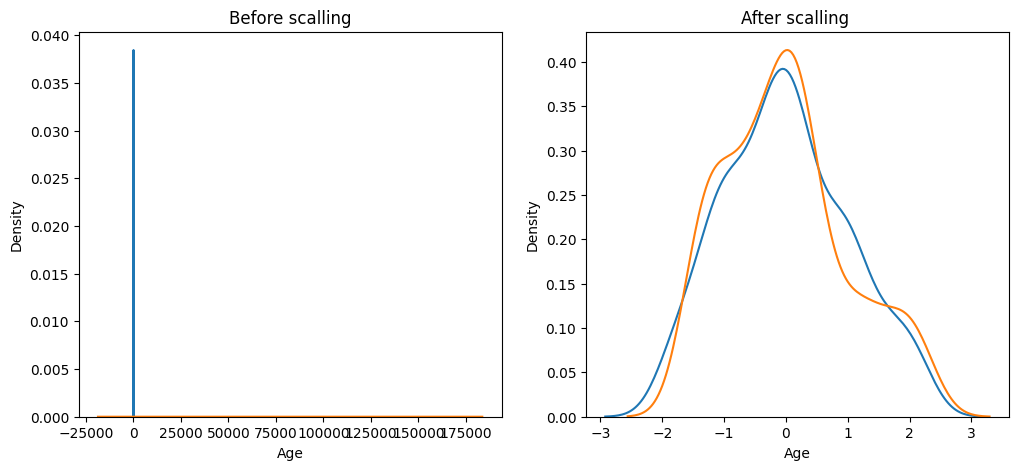

In [10]:
fig, (ax1, ax2) = plt.subplots(ncols=2 ,figsize = (12,5))
#setting title 
ax1.set_title('Before scalling')
ax2.set_title('After scalling ')
# ploting graphs 
#G1
sns.kdeplot(X_train['Age'],ax =ax1)
sns.kdeplot(X_train['EstimatedSalary'],ax =ax1)
#G2
sns.kdeplot(X_train_scaled['Age'],ax =ax2)
sns.kdeplot(X_train_scaled['EstimatedSalary'],ax =ax2)
plt.show()

<h2>why scalling is important <h2/>

In [11]:
from sklearn.linear_model import LogisticRegression

In [17]:
lr =LogisticRegression()
lr_scaled =LogisticRegression()

In [19]:
lr.fit(X_train,y_train)
lr_scaled.fit(X_train_scaled,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [20]:
y_pred =lr.predict(X_test)
y_pred_scaled = lr_scaled.predict(X_test_scaled)

In [21]:
from sklearn.metrics import accuracy_score

In [16]:
print("Actual :", accuracy_score(y_test,y_pred))
print("scaled :", accuracy_score(y_test,y_pred_scaled))

Actual : 0.875
scaled : 0.8666666666666667
